In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("NYC Taxi EDA") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/04/25 00:43:21 WARN Utils: Your hostname, giorgos-B550M-AORUS-ELITE, resolves to a loopback address: 127.0.1.1; using 192.168.2.8 instead (on interface enp5s0)
26/04/25 00:43:21 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/25 00:43:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.1.1


In [2]:
df = spark.read.csv("../data/yellow_tripdata_2016-03.csv", header=True, inferSchema=True)

print("Rows:", df.count())
print("Columns:", len(df.columns))
df.printSchema()

Rows: 12210952
Columns: 19
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)



In [3]:
df.show(5, truncate=False)

+--------+--------------------+---------------------+---------------+-------------+------------------+------------------+----------+------------------+------------------+-----------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|pickup_longitude  |pickup_latitude   |RatecodeID|store_and_fwd_flag|dropoff_longitude |dropoff_latitude |payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|
+--------+--------------------+---------------------+---------------+-------------+------------------+------------------+----------+------------------+------------------+-----------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+
|1       |2016-03-01 00:00:00 |2016-03-01 00:07:55  |1              |2.5          |-73.97674560546875|40.76515197753906 |1         |N      

In [4]:
from pyspark.sql.functions import col, sum as spark_sum

null_counts = df.select([
    spark_sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
])

null_counts.show(vertical=True)

-RECORD 0--------------------
 VendorID              | 0   
 tpep_pickup_datetime  | 0   
 tpep_dropoff_datetime | 0   
 passenger_count       | 0   
 trip_distance         | 0   
 pickup_longitude      | 0   
 pickup_latitude       | 0   
 RatecodeID            | 0   
 store_and_fwd_flag    | 0   
 dropoff_longitude     | 0   
 dropoff_latitude      | 0   
 payment_type          | 0   
 fare_amount           | 0   
 extra                 | 0   
 mta_tax               | 0   
 tip_amount            | 0   
 tolls_amount          | 0   
 improvement_surcharge | 0   
 total_amount          | 0   



In [5]:
df.select(
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "passenger_count"
).describe().show()

26/04/25 00:46:47 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+------------------+------------------+-----------------+------------------+
|summary|     trip_distance|       fare_amount|        tip_amount|     total_amount|   passenger_count|
+-------+------------------+------------------+------------------+-----------------+------------------+
|  count|          12210952|          12210952|          12210952|         12210952|          12210952|
|   mean| 6.131769762914482|12.795078448428898| 1.792581815897803|16.04581967493267| 1.659580022917132|
| stddev|6156.4826446949155|134.09792335003755|2.5491241397467626|134.3577728869804|1.3121892188373814|
|    min|               0.0|            -376.0|             -20.0|           -376.3|                 0|
|    max|      1.90726288E7|         429496.72|             850.0|        429562.25|                 9|
+-------+------------------+------------------+------------------+-----------------+------------------+



In [6]:
from pyspark.sql.functions import round as spark_round, unix_timestamp

# Add trip duration in minutes
df = df.withColumn(
    "trip_duration_min",
    spark_round((unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60, 2)
)

# Show min/max of key columns to spot garbage values
df.select(
    "trip_duration_min",
    "trip_distance",
    "fare_amount",
    "total_amount"
).describe().show()

+-------+------------------+------------------+------------------+-----------------+
|summary| trip_duration_min|     trip_distance|       fare_amount|     total_amount|
+-------+------------------+------------------+------------------+-----------------+
|  count|          12210952|          12210952|          12210952|         12210952|
|   mean|15.679099870345706| 6.131769762914482|12.795078448428898|16.04581967493267|
| stddev|115.17475126125541|6156.4826446949155|134.09792335003755|134.3577728869804|
|    min|         -50460.23|               0.0|            -376.0|           -376.3|
|    max|         145807.87|      1.90726288E7|         429496.72|        429562.25|
+-------+------------------+------------------+------------------+-----------------+



In [7]:
df_clean = df.filter(
    (col("trip_duration_min") > 1) &        # at least 1 minute
    (col("trip_duration_min") < 180) &      # at most 3 hours
    (col("trip_distance") > 0.1) &          # at least 0.1 miles
    (col("trip_distance") < 100) &          # at most 100 miles
    (col("fare_amount") > 0) &              # no negative/zero fares
    (col("passenger_count") >= 1) &         # at least 1 passenger
    (col("passenger_count") <= 6) &         # max 6 passengers
    (col("pickup_longitude").between(-74.3, -73.7)) &   # NYC bounds
    (col("pickup_latitude").between(40.5, 40.9))        # NYC bounds
)

print("Rows before cleaning:", df.count())
print("Rows after cleaning:", df_clean.count())
print("Rows removed:", df.count() - df_clean.count())

Rows before cleaning: 12210952


Rows after cleaning: 11891533


Rows removed: 319419


In [8]:
df_clean.select(
    "trip_duration_min",
    "trip_distance",
    "fare_amount",
    "passenger_count"
).describe().show()

+-------+------------------+------------------+------------------+------------------+
|summary| trip_duration_min|     trip_distance|       fare_amount|   passenger_count|
+-------+------------------+------------------+------------------+------------------+
|  count|          11891533|          11891533|          11891533|          11891533|
|   mean|13.743684692293005| 2.976292224896466|12.706952098606624|1.6640478565715624|
| stddev|10.472652586298587|3.6090963941304857|10.448830662058048|1.3164257931148315|
|    min|              1.02|              0.11|              0.01|                 1|
|    max|            179.63|              93.0|            1426.0|                 6|
+-------+------------------+------------------+------------------+------------------+



In [9]:
from pyspark.sql.functions import hour, dayofweek, month

df_clean = df_clean.withColumn("pickup_hour", hour("tpep_pickup_datetime")) \
                   .withColumn("pickup_dayofweek", dayofweek("tpep_pickup_datetime")) \
                   .withColumn("pickup_month", month("tpep_pickup_datetime"))

df_clean.select("tpep_pickup_datetime", "pickup_hour", "pickup_dayofweek", "pickup_month").show(5)

+--------------------+-----------+----------------+------------+
|tpep_pickup_datetime|pickup_hour|pickup_dayofweek|pickup_month|
+--------------------+-----------+----------------+------------+
| 2016-03-01 00:00:00|          0|               3|           3|
| 2016-03-01 00:00:00|          0|               3|           3|
| 2016-03-01 00:00:00|          0|               3|           3|
| 2016-03-01 00:00:01|          0|               3|           3|
| 2016-03-01 00:00:01|          0|               3|           3|
+--------------------+-----------+----------------+------------+
only showing top 5 rows


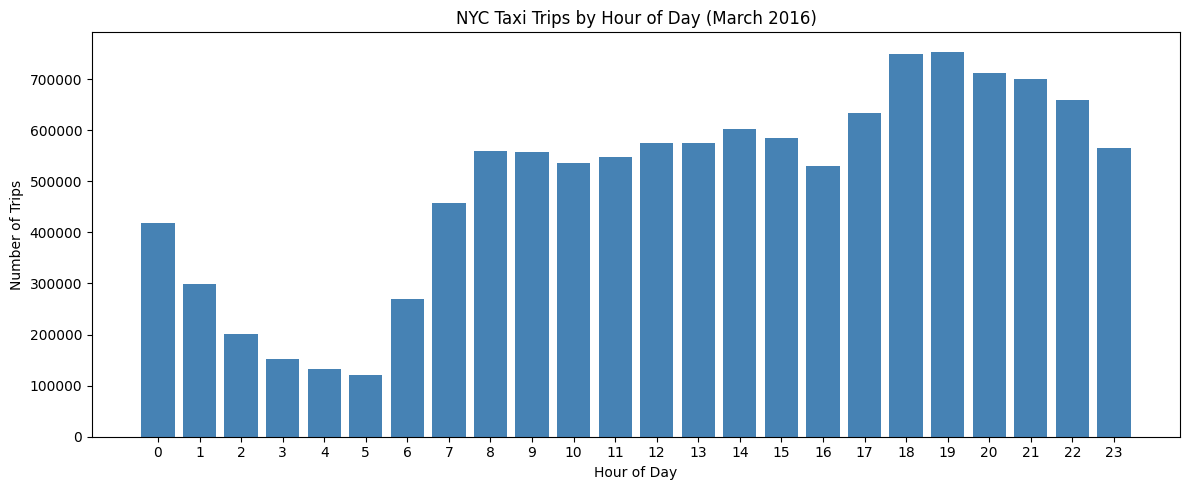

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

# Count trips per hour (convert to pandas for plotting)
hourly = df_clean.groupBy("pickup_hour").count().orderBy("pickup_hour").toPandas()

plt.figure(figsize=(12, 5))
plt.bar(hourly["pickup_hour"], hourly["count"], color="steelblue")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.title("NYC Taxi Trips by Hour of Day (March 2016)")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("../results/trips_by_hour.png", dpi=150)
plt.show()

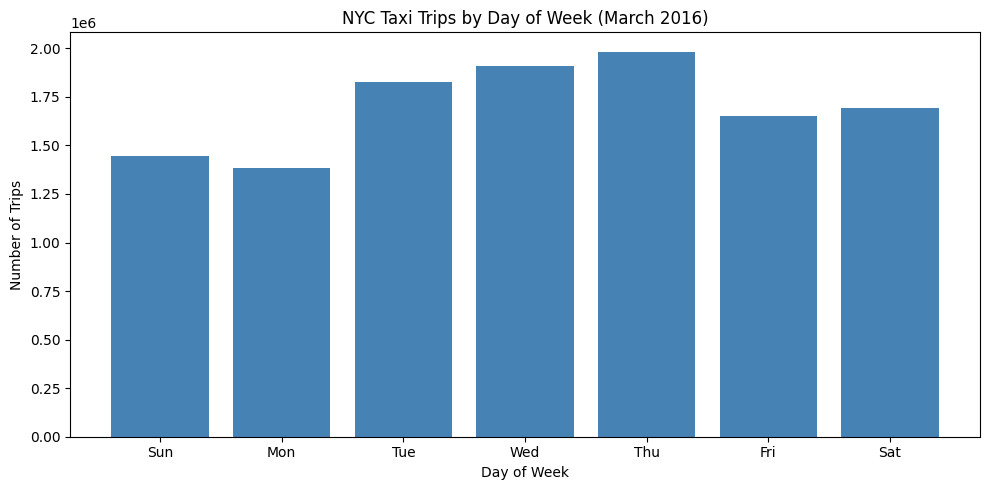

In [11]:
# In PySpark: 1=Sunday, 2=Monday, ..., 7=Saturday
day_labels = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}

daily = df_clean.groupBy("pickup_dayofweek").count().orderBy("pickup_dayofweek").toPandas()
daily["day_name"] = daily["pickup_dayofweek"].map(day_labels)

plt.figure(figsize=(10, 5))
plt.bar(daily["day_name"], daily["count"], color="steelblue")
plt.xlabel("Day of Week")
plt.ylabel("Number of Trips")
plt.title("NYC Taxi Trips by Day of Week (March 2016)")
plt.tight_layout()
plt.savefig("../results/trips_by_day.png", dpi=150)
plt.show()

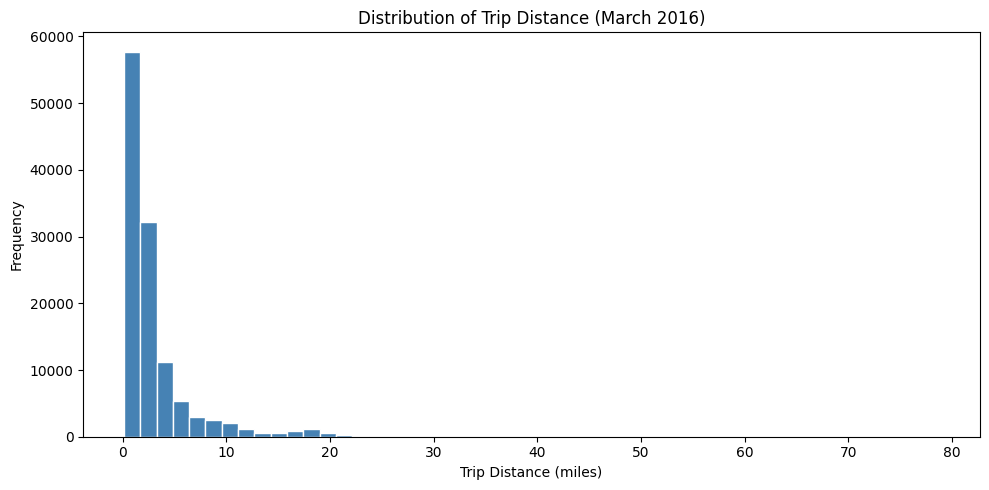

In [14]:
# Sample 100k rows for plotting (can't plot 12M points)
sample = df_clean.select("trip_distance").sample(fraction=0.01).toPandas()

plt.figure(figsize=(10, 5))
plt.hist(sample["trip_distance"], bins=50, color="steelblue", edgecolor="white")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Frequency")
plt.title("Distribution of Trip Distance (March 2016)")
plt.tight_layout()
plt.savefig("../results/trip_distance_dist.png", dpi=150)
plt.show()